# Práctica 2 — Introducción al aprendizaje supervisado

**Machine Learning · Máster Universitario en Inteligencia Artificial · curso 2026/2027**

Grupo: *4* · Integrantes: *Carlos Chapman Peña*, *Miguel Ángel Gordillo Masero*, *María Xiaolan Ríos Díaz*, *Pablo Sola Díaz*

---

Cuaderno **de partida**. La primera celda de código fija vuestro grupo y vuestra semilla y carga
los datos; la última escribe los dos ficheros que subís a Kaggle. **Entre medias, el cuaderno es
vuestro**: los títulos de los ejercicios solo marcan el orden. La interpretación va en celdas
Markdown, no en comentarios de Python.

## 0. Entorno, semilla y datos

Declarad `GRUPO` y `SEMILLA` antes de nada. **Toda la aleatoriedad del cuaderno sale de
`SEMILLA`**: las particiones de la validación, los desempates y cualquier `random_state`.

In [2]:
# --- Práctica 2: grupo, semilla, entorno y datos --------------------------------
GRUPO = 4        # vuestro número de grupo (entero)
SEMILLA = 67      # vuestra semilla (entero): toda la aleatoriedad sale de aquí

import os, sys, platform
import numpy as np, pandas as pd, matplotlib, sklearn, scipy
import matplotlib.pyplot as plt

assert isinstance(GRUPO, int) and isinstance(SEMILLA, int), "Declarad GRUPO y SEMILLA (enteros) antes de seguir."

DATOS = os.path.join("..", "Datos")                  # relativa a este cuaderno
sys.path.insert(0, os.path.join("..", "Codigo"))     # código proporcionado por el curso
from oner import OneRClassifier, OneRRegressor
from comprobar_estimador import comprobar_estimador

ciber_train = pd.read_csv(os.path.join(DATOS, "ciber_train.csv"))
ciber_test = pd.read_csv(os.path.join(DATOS, "ciber_test.csv"))
latencia_train = pd.read_csv(os.path.join(DATOS, "latencia_train.csv"))
latencia_test = pd.read_csv(os.path.join(DATOS, "latencia_test.csv"))

X_CIBER = [c for c in ciber_test.columns if c != "id"]          # características de ciber
X_LATENCIA = [c for c in latencia_test.columns if c != "id"]    # características de latencia

print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("GRUPO       ", GRUPO, "· SEMILLA", SEMILLA)
print("ciber       ", ciber_train.shape, ciber_test.shape)
print("latencia    ", latencia_train.shape, latencia_test.shape)

python       3.12.10
numpy        2.5.4
pandas       3.1.0
scikit-learn 1.9.1
GRUPO        4 · SEMILLA 67
ciber        (5000, 13) (5000, 12)
latencia     (5000, 11) (3000, 10)


## Ejercicio 1. Cómo vais a medir



### 1(a) Datos de ciber_train

In [3]:
ciber_train.info()
print("Valores ausentes en entrenamiento:", ciber_train.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            5000 non-null   str    
 1   proto         5000 non-null   str    
 2   service       5000 non-null   str    
 3   conn_state    5000 non-null   str    
 4   duration      5000 non-null   float64
 5   src_bytes     5000 non-null   int64  
 6   dst_bytes     5000 non-null   int64  
 7   missed_bytes  5000 non-null   int64  
 8   src_pkts      5000 non-null   int64  
 9   src_ip_bytes  5000 non-null   int64  
 10  dst_pkts      5000 non-null   int64  
 11  dst_ip_bytes  5000 non-null   int64  
 12  attack_type   5000 non-null   str    
dtypes: float64(1), int64(7), str(5)
memory usage: 507.9 KB
Valores ausentes en entrenamiento: 0


Con `.info()` comprobamos que el conjunto de entrenamiento tiene 5000 patrones y 13 columnas, sin valores
ausentes. `id` es un identificador y no se usa como característica; `attack_type` es la variable objetivo.
Las 11 características restantes son de dos tipos:

| Tipo | Características |
|---|---|
| Nominales (3) | `proto`, `service`, `conn_state` |
| Numéricas (8) | `duration` (segundos, real) y siete recuentos enteros: `src_bytes`, `dst_bytes`, `missed_bytes`, `src_pkts`, `src_ip_bytes`, `dst_pkts`, `dst_ip_bytes` |

Al combinar tipos nominales y numéricos, para usar KNN habrá que decidir cómo representar las nominales para que
una distancia entre patrones tenga sentido (Ejercicio 3a).

In [4]:
NOM_CIBER = ["proto", "service", "conn_state"]
NUM_CIBER = [c for c in X_CIBER if c not in NOM_CIBER]

resumen = ciber_train[NUM_CIBER].describe(percentiles=[.25, .5, .75, .99]).T
resumen["% ceros"] = (ciber_train[NUM_CIBER] == 0).mean().mul(100).round(1)
resumen["asimetría"] = ciber_train[NUM_CIBER].skew().round(1)
display(resumen.drop(columns="count").round(2))

,mean,std,min,25%,50%,75%,99%,max,% ceros,asimetría
duration,7.24,39.31,0.0,0.0,0.19,0.4,152.81,1.801540e+03,1.4,23.5
src_bytes,447347.17,19451141.48,0.0,0.0,0.00,150.5,4839.02,9.516904e+08,51.1,46.3
dst_bytes,455961.87,19457025.58,0.0,0.0,0.00,285.0,12183.00,9.517448e+08,53.9,46.3
missed_bytes,449594.32,26707848.35,0.0,0.0,0.00,0.0,1251.97,1.854527e+09,98.2,67.4
src_pkts,34.52,72.72,0.0,1.0,4.00,100.0,120.00,2.828000e+03,8.1,15.7
src_ip_bytes,1692.95,3863.06,0.0,72.0,356.00,4800.0,6054.46,1.759590e+05,8.1,23.8
dst_pkts,2.70,20.63,0.0,0.0,1.00,2.0,17.00,1.311000e+03,38.6,53.2
dst_ip_bytes,1425.55,28928.45,0.0,0.0,60.00,340.0,12815.00,1.925805e+06,38.6,60.5


La tabla resume las 8 características numéricas, a las que añadimos el porcentaje de ceros y el coeficiente de
asimetría (0 para una distribución simétrica; positivo cuando hay una cola larga hacia valores altos).

**Escalas muy distintas.** Todas empiezan en 0, pero sus máximos van de unos $10^3$ (`duration`: 1801 s,
`src_pkts`: 2828) a unos $10^9$ (`src_bytes`: $9.5 \cdot 10^8$, `missed_bytes`: $1.9 \cdot 10^9$). Las
características en bytes tienen diferencias numéricamente mucho mayores que las de paquetes o duración.

**Distribuciones extremadamente asimétricas.** La asimetría va de 15.7 (`src_pkts`) a 67.4 (`missed_bytes`).
La mayoría de los patrones toman valores pequeños y unos pocos, valores enormes: en `src_bytes` la mediana
es 0, el percentil 99 es 4839 y la media, 447 347, **supera incluso al percentil 99**. La media y la desviación
típica no representan un patrón típico; la mediana y los percentiles sí.

**Muchos ceros.** `missed_bytes` vale 0 en el 98.2 % de los patrones, `src_bytes` y `dst_bytes` en más de la
mitad, y `dst_pkts` y `dst_ip_bytes` en el 38.6 %. Un cero aquí tiene significado (una conexión sin bytes de
respuesta, por ejemplo) y no es un valor ausente.

**Consecuencia para KNN.** La distancia euclídea suma diferencias al cuadrado de todas las características. Con
estas escalas, las características en bytes dominarían la distancia por su magnitud, no por ser más informativas,
y la cola de valores extremos haría que la mayoría de los patrones queden comprimidos cerca de 0. Cómo
transformar las numéricas es por tanto una decisión clave, que compararemos en el Ejercicio 3a.

,patrones,%
attack_type,,
normal,2998,59.96
xss,300,6.00
ddos,300,6.00
password,300,6.00
injection,300,6.00
dos,300,6.00
scanning,252,5.04
backdoor,100,2.00
mitm,100,2.00


Desbalanceo (mayoritaria / minoritaria): 60.0


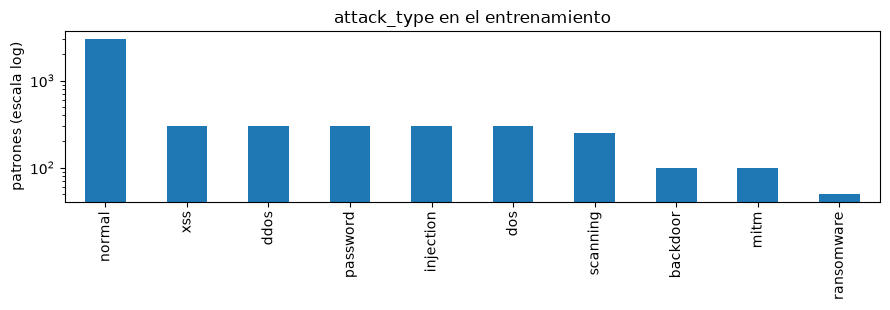

In [5]:
y_ciber = ciber_train["attack_type"]
dist = pd.DataFrame({"patrones": y_ciber.value_counts(),
                     "%": y_ciber.value_counts(normalize=True).mul(100).round(2)})
display(dist)
print(f"Desbalanceo (mayoritaria / minoritaria): {dist['patrones'].max() / dist['patrones'].min():.1f}")

fig, ax = plt.subplots(figsize=(9, 3.2))
dist["patrones"].plot.bar(ax=ax, color="C0")
ax.set_yscale("log"); ax.set_ylabel("patrones (escala log)"); ax.set_xlabel("")
ax.set_title("attack_type en el entrenamiento")
plt.tight_layout(); plt.show()

La variable objetivo, `attack_type`, tiene 10 clases: tráfico `normal` y nueve tipos de ataque. Su distribución
está muy desbalanceada:

| Grupo | Clases | Patrones por clase | % |
|---|---|---:|---:|
| Mayoritaria | `normal` | 2998 | 60.0 |
| Intermedias | `xss`, `ddos`, `password`, `injection`, `dos` | 300 | 6.0 |
| | `scanning` | 252 | 5.0 |
| Raras | `backdoor`, `mitm` | 100 | 2.0 |
| | `ransomware` | 50 | 1.0 |

La clase mayoritaria tiene 60 veces más patrones que la minoritaria. Según el enunciado, el test mantiene estas
proporciones, así que en él las clases raras también serán muy pocas y su F1 se calculará con muy pocos patrones.

**Por qué importa con esta métrica.** El F1 macro es la media sin ponderar del F1 de las diez clases:
`ransomware`, con 50 patrones, pesa en la puntuación exactamente lo mismo que `normal`, con 2998. Un modelo
que acierte casi todo el tráfico normal pero falle las clases raras tendrá una exactitud (CCR) alta y un F1
macro bajo. Esto tiene dos consecuencias:
- La CCR no sirve para comparar modelos en este problema; lo comprobaremos con ZeroR en el Ejercicio 2a.
- Con tan pocos patrones de las clases raras, el protocolo de validación tiene que asegurar que todas las
  clases aparezcan en cada partición de validación, en su proporción (Ejercicio 1b).

In [6]:
for c in NOM_CIBER:
    print(f"\n{c}: {ciber_train[c].nunique()} categorías")
    display(pd.crosstab(ciber_train[c], y_ciber, margins=True, margins_name="total"))


proto: 3 categorías


attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss,total
proto,,,,,,,,,,,
icmp,0,0,0,0,6,15,0,0,0,0,21
tcp,100,214,253,288,44,1424,299,50,228,265,3165
udp,0,86,47,12,50,1559,1,0,24,35,1814
total,100,300,300,300,100,2998,300,50,252,300,5000



service: 8 categorías


attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss,total
service,,,,,,,,,,,
-,96,183,247,35,17,1355,26,50,223,95,2327
dce_rpc,1,0,0,0,0,0,0,0,0,0,1
dns,0,86,47,12,48,1500,0,0,24,35,1752
ftp,0,0,0,0,0,0,11,0,0,0,11
http,0,24,1,253,4,102,262,0,1,170,817
smb,2,0,0,0,0,0,0,0,0,0,2
smb;gssapi,1,0,0,0,0,0,0,0,0,0,1
ssl,0,7,5,0,31,41,1,0,4,0,89
total,100,300,300,300,100,2998,300,50,252,300,5000



conn_state: 13 categorías


attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss,total
conn_state,,,,,,,,,,,
OTH,0,2,0,1,6,23,0,49,0,5,86
REJ,96,0,175,0,0,0,24,0,217,0,512
RSTO,0,0,30,2,3,13,0,0,5,0,53
RSTOS0,0,0,0,0,1,2,0,0,0,3,6
RSTR,3,0,0,0,3,8,7,0,0,37,58
RSTRH,0,0,0,0,0,4,0,0,0,5,9
S0,0,3,41,0,1,1766,1,0,1,26,1839
S1,0,91,0,7,0,1,0,0,0,14,113
S2,0,1,0,7,1,2,0,0,0,2,13


Las tablas cruzan cada característica nominal con la clase. La columna `total` da la frecuencia de cada categoría.

**Cardinalidad y categorías raras.** `proto` tiene 3 categorías, `service` 8 y `conn_state` 13. Varias son
muy poco frecuentes: en `proto`, `icmp` (21 patrones); en `service`, `ftp` (11), `smb` (2), `dce_rpc` y
`smb;gssapi` (1 cada una); en `conn_state`, `RSTOS0` (6).

**Algunas categorías casi identifican una clase:**
- 49 de los 50 patrones de `ransomware` tienen `conn_state = OTH`.
- Los 11 patrones con `service = ftp` son `password`.
- Los 4 patrones con `smb`, `dce_rpc` o `smb;gssapi` son `backdoor`.
- `conn_state = S0` (1839 patrones) es casi exclusivamente `normal` (1766).

**Otras mezclan varias clases:**
- `conn_state = REJ` agrupa `scanning` (217), `dos` (175), `backdoor` (96) y `password` (24).
- `service = http` agrupa `password` (262), `injection` (253) y `xss` (170).

**Consecuencias.** Las nominales son muy informativas, pero ninguna separa por sí sola todas las clases: dentro
de `REJ` o de `http`, la distinción tendrá que venir de otras características. Además, al ser categorías sin orden,
habrá que representarlas de forma que una distancia entre patrones tenga sentido (Ejercicio 3a), teniendo en
cuenta que algunas categorías tienen muy pocos patrones. Las clases que comparten categorías (`scanning`, `dos`,
`backdoor` en `REJ`; `password`, `injection`, `xss` en `http`) son candidatas a confundirse entre sí, lo que
comprobaremos en la matriz de confusión (Ejercicio 3c).

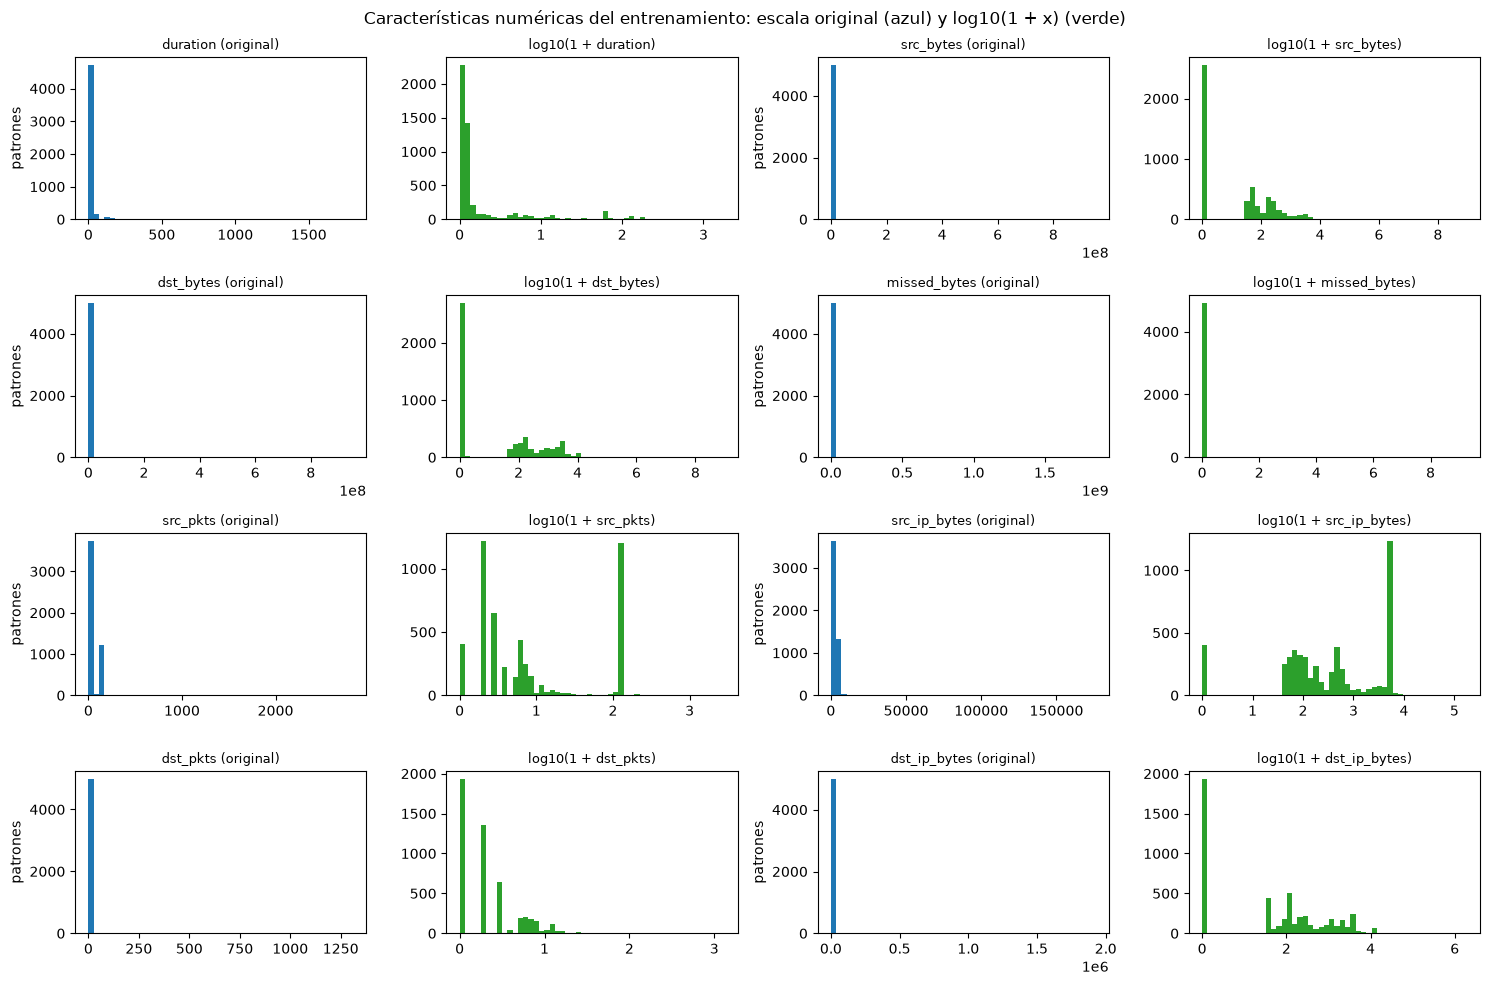

In [7]:
fig, axs = plt.subplots(4, 4, figsize=(15, 10))
for i, c in enumerate(NUM_CIBER):
    ax_orig, ax_log = axs[i // 2, 2 * (i % 2)], axs[i // 2, 2 * (i % 2) + 1]
    ax_orig.hist(ciber_train[c], bins=50, color="C0")
    ax_orig.set_title(f"{c} (original)", fontsize=9)
    ax_log.hist(np.log10(ciber_train[c] + 1), bins=50, color="C2")
    ax_log.set_title(f"log10(1 + {c})", fontsize=9)
for ax in axs[:, [0, 2]].ravel():
    ax.set_ylabel("patrones")
fig.suptitle("Características numéricas del entrenamiento: escala original (azul) y log10(1 + x) (verde)")
plt.tight_layout(); plt.show()

Los histogramas muestran las 8 numéricas en escala original (azul) y en escala $\log_{10}(1+x)$ (verde).

**Por qué esta transformación.** Los valores van de 0 a $10^9$, así que en escala original casi todo queda
aplastado junto al 0. El logaritmo convierte esas diferencias multiplicativas en diferencias sumadas, de forma
que cada orden de magnitud ocupa el mismo espacio en el eje: de 10 a 100 bytes se ve igual que de $10^6$ a $10^7$.
El problema es que $\log_{10}(0)$ no está definido, y muchas de estas características valen 0 en gran parte de
los patrones. Sumar 1 antes del logaritmo lo resuelve: un 0 se representa en 0 y, para valores grandes, sumar 1
apenas cambia el resultado. Aquí la usamos solo para visualizar los datos; si conviene usarla como
preprocesamiento se decidirá en el Ejercicio 3a.

En escala original no se distingue la distribución: casi todos los patrones se concentran junto al 0 y unos
pocos valores extremos estiran el eje. Solo en `src_pkts` y `src_ip_bytes` se aprecia una segunda barra, que
analizamos en la celda siguiente.

La escala logarítmica permite ver la forma, que sigue lejos de ser simétrica:
- En las características de **bytes** hay una gran masa de ceros y, separado, un grupo de conexiones con datos.
  `missed_bytes` es prácticamente siempre 0.
- En las de **paquetes** los valores son enteros pequeños y forman barras aisladas, con un pico muy marcado en
  `src_pkts` (y en `src_ip_bytes`).
- `duration` concentra casi todo cerca de 0, con una cola de conexiones largas.

**Consecuencia.** El logaritmo reduce mucho la diferencia de escalas, pero no elimina las masas de ceros ni los
picos. Qué transformación funciona mejor para KNN no se deduce de estas figuras: se decidirá comparando opciones
con validación en el Ejercicio 3a.

In [8]:
# Que valor exacto forma el pico de los histogramas
for c in ["src_pkts", "src_ip_bytes"]:
    display(ciber_train[c].value_counts().head(3).to_frame().T)

# A que clase pertenecen las filas de ese pico
pico = ciber_train[(ciber_train["src_pkts"] == 120) & (ciber_train["src_ip_bytes"] == 4800)]
print("Patrones con src_pkts = 120 y src_ip_bytes = 4800:", len(pico))
display(pico["attack_type"].value_counts())
print(f"Fracción del trafico normal: {len(pico) / (y_ciber == 'normal').sum():.1%}")

src_pkts,1,120,2
count,1218,1203,653


src_ip_bytes,4800,0,44
count,1203,403,171


Patrones con src_pkts = 120 y src_ip_bytes = 4800: 1203


attack_type
normal    1203
Name: count, dtype: int64

Fracción del trafico normal: 40.1%


Para identificar las barras que destacaban en `src_pkts` y `src_ip_bytes`, buscamos sus valores más
frecuentes: 120 paquetes y 4800 bytes aparecen 1203 veces cada uno, y corresponden a los mismos patrones.
Los 1203 son tráfico `normal`: el 40 % de todo el tráfico normal envía exactamente 4800 bytes en 120 paquetes.

**Consecuencia para KNN.** Esa zona del espacio estará muy poblada y será muy homogénea: un patrón con ese
perfil tendrá muchos vecinos `normal` a distancia casi nula. El tráfico normal no es una única nube, sino
al menos un bloque muy compacto y otro más disperso.

In [9]:
# Mediana de cada numérica por clase: cómo es una conexión típica de cada tipo
display(ciber_train.groupby("attack_type")[NUM_CIBER].median().round(2).T)

attack_type,backdoor,ddos,dos,injection,mitm,normal,password,ransomware,scanning,xss
duration,0.0,0.16,0.0,0.22,0.21,0.21,0.01,0.0,0.02,5.2
src_bytes,0.0,0.00,0.0,258.50,168.00,0.00,155.00,0.0,0.00,1943.5
dst_bytes,0.0,0.00,0.0,1951.00,436.00,0.00,978.00,0.0,0.00,1218.5
missed_bytes,0.0,0.00,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.0
src_pkts,1.0,2.00,2.0,5.00,4.00,4.00,5.00,1.0,1.00,6.0
src_ip_bytes,48.0,112.00,80.0,528.00,280.00,488.00,421.00,435.0,44.00,2114.0
dst_pkts,1.0,1.00,1.0,6.00,3.00,0.00,5.00,0.0,1.00,4.0
dst_ip_bytes,40.0,86.00,44.0,2239.00,492.00,0.00,1150.00,0.0,40.00,1320.5


La tabla muestra el **perfil numérico** de cada clase. Cada columna es una clase y cada fila una característica;
cada valor es la mediana de esa característica entre los patrones de esa clase, es decir, el valor que deja la mitad
de sus conexiones por debajo y la otra mitad por encima. Por ejemplo, la columna de `backdoor` indica que la mitad de
sus conexiones envían 1 paquete o menos y 48 bytes o menos. Leer una columna entera da una idea de cómo es una
conexión habitual de ese tipo de ataque. Usamos la mediana y no la media porque, con distribuciones tan asimétricas,
unos pocos valores extremos pueden afectar mucho a la media.

- Las numéricas **distinguen algunas clases**: `xss`, `injection`, `password` y `mitm` son las únicas que
  intercambian datos (`src_bytes` y `dst_bytes` distintos de 0), y `xss` es la que más bytes envía y la que más dura.
  Esto ayuda a separar las clases que comparten `service = http`
- Otras clases **son casi indistinguibles**: `backdoor` y `scanning` tienen un perfil prácticamente idéntico,
  conexiones de 1 paquete y unos 40–48 bytes sin datos. Como además comparten `conn_state = REJ`, es de esperar
  que se confundan entre sí
- Algunas características **apenas aportan**: `missed_bytes` tiene mediana 0 en todas las clases

**Consecuencia.** No todas las características son igual de útiles para distinguir las clases, y algunas solo lo
son para ciertos pares de clases. Esto puede ser útil e importante al decidir cómo se construye la distancia de KNN, en el
preprocesamiento y en el diseño de nuestra variante.

In [10]:
print("Patrones con características repetidas en el entrenamiento:",
      ciber_train.duplicated(subset=X_CIBER).sum())

Patrones con características repetidas en el entrenamiento: 0


No hay dos patrones de entrenamiento con exactamente las mismas características: cada fila es una conexión
distinta. No hay grupos de filas relacionadas que debamos mantener juntas al validar.

**Finalmente** 


*¿Qué hace difícil este problema?*

1. **Desbalanceo con F1 macro.** `ransomware` (50 patrones) pesa en la métrica lo mismo que `normal` (2998). Un
   modelo que falle las clases raras tendrá una CCR alta y un F1 macro bajo. La CCR no sirve para comparar
   modelos, y el protocolo tiene que asegurar que las clases raras aparezcan en cada partición de
   validación.
2. **Escalas muy distintas y distribuciones muy asimétricas.** Las numéricas van de $10^3$ a $10^9$, con muchos
   ceros y picos. Sin transformar, las de bytes dominarían la distancia de KNN por su magnitud. La transformación de las numéricas se decidirá comparando opciones.
3. **Tipos mezclados.** Hay tres nominales, algunas con categorías de muy pocos patrones, que hay que representar
   para que una distancia tenga sentido. Codificación de las nominales.
4. **Clases que se solapan.** `scanning`, `dos` y `backdoor` comparten `conn_state = REJ`, y `backdoor` y `scanning`
   tienen además un perfil numérico casi idéntico; `password`, `injection` y `xss` comparten `service = http`. Lo comprobaremos en la matriz de confusión.
5. **Sin duplicados ni grupos.** Cada fila es una conexión independiente. → Basta una partición estratificada; no
   hace falta validación agrupada.

### 1(b) Protocolos de validación — ciberseguridad

In [11]:
# --- 1(b) Protocolos de validación en ciber ---------------------------------------
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (StratifiedKFold, KFold, RepeatedStratifiedKFold,
                                     StratifiedShuffleSplit, cross_val_score)

# Datos: sin la columna id y con el objetivo aparte
X_ciber = ciber_train[X_CIBER]
y_ciber = ciber_train["attack_type"]

NOMINALES_CIBER = ["proto", "service", "conn_state"]
NUMERICAS_CIBER = [c for c in X_CIBER if c not in NOMINALES_CIBER]

# Modelo con el que se comparan los protocolos: KNN K=5, log1p + estandarizar.
# Todo el preprocesamiento va dentro del Pipeline: se ajusta solo con cada entrenamiento.
modelo_ciber_cv = Pipeline([
    ("pre", ColumnTransformer([
        ("nom", OneHotEncoder(handle_unknown="ignore"), NOMINALES_CIBER),
        ("num", Pipeline([("log", FunctionTransformer(np.log1p)),
                          ("esc", StandardScaler())]), NUMERICAS_CIBER),
    ])),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

protocolos_ciber = {
    "Holdout 80/20 estrat.":   lambda s: StratifiedShuffleSplit(1, test_size=0.2, random_state=s),
    "5-fold sin estratificar": lambda s: KFold(5, shuffle=True, random_state=s),
    "5-fold estratificado":    lambda s: StratifiedKFold(5, shuffle=True, random_state=s),
    "10-fold estratificado":   lambda s: StratifiedKFold(10, shuffle=True, random_state=s),
    "5x3 estratificado":       lambda s: RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=s),
}

# Cada protocolo se repite con 8 semillas derivadas de SEMILLA: la dispersión entre
# semillas mide cuánto se puede fiar uno de la estimación.
N_SEMILLAS = 8
resultados = {}
for nombre, crear_cv in protocolos_ciber.items():
    medias = []
    for i in range(N_SEMILLAS):
        puntuaciones = cross_val_score(modelo_ciber_cv, X_ciber, y_ciber,
                                       cv=crear_cv(SEMILLA + i),
                                       scoring="f1_macro", n_jobs=-1)
        medias.append(puntuaciones.mean())
    resultados[nombre] = {"media": np.mean(medias),
                          "desv entre semillas": np.std(medias),
                          "rango": np.ptp(medias)}

tabla_protocolos_ciber = pd.DataFrame(resultados).T.round(4)
display(tabla_protocolos_ciber)

# Ejemplares de la clase rara en cada pliegue de validación (efecto de estratificar)
es_ransomware = (y_ciber == "ransomware").to_numpy()
for nombre, cv in [("5-fold sin estratificar", KFold(5, shuffle=True, random_state=SEMILLA)),
                   ("5-fold estratificado", StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
                   ("10-fold estratificado", StratifiedKFold(10, shuffle=True, random_state=SEMILLA))]:
    print(f"{nombre:25s} ransomware por pliegue:",
          [int(es_ransomware[val].sum()) for _, val in cv.split(X_ciber, y_ciber)])

,media,desv entre semillas,rango
Holdout 80/20 estrat.,0.9162,0.0095,0.0250
5-fold sin estratificar,0.9188,0.0024,0.0081
5-fold estratificado,0.9188,0.0028,0.0087
10-fold estratificado,0.9210,0.0015,0.0051
5x3 estratificado,0.9193,0.0014,0.0042


5-fold sin estratificar   ransomware por pliegue: [8, 7, 18, 7, 10]
5-fold estratificado      ransomware por pliegue: [10, 10, 10, 10, 10]
10-fold estratificado     ransomware por pliegue: [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]




**Protocolos probados.** Holdout estratificado 80/20, 5-fold sin estratificar, 5-fold
estratificado, 10-fold estratificado y 5-fold estratificado repetido 3 veces (5×3), todos con
F1 macro, que es la métrica de la competición. Para comparar protocolos se usa un mismo modelo
(KNN con K=5, `log1p` y estandarización dentro del `Pipeline`) y se repite cada protocolo con
8 semillas derivadas de `SEMILLA`. Lo que se mide es cuánto cambia la estimación al cambiar la
semilla de las particiones: si cambia mucho, no se pueden distinguir dos modelos parecidos.

**Resultado.** [pegar la tabla]. Las medias son casi idénticas (0.919–0.921) salvo el holdout,
pero la dispersión entre semillas no: el holdout varía 0.0095 (rango 0.025), unas siete veces más
que 5×3 (0.0014, rango 0.0042). Con una sola partición de 1000 patrones, y solo 10 de la clase
rara `ransomware`, la estimación depende demasiado de qué patrones caen en validación.

**Por qué estratificar.** El test tiene las mismas proporciones de clases que el entrenamiento,
y la estratificación reproduce esa construcción en cada pliegue. Sin estratificar,
`ransomware` (50 patrones) aparece entre 7 y 18 veces por pliegue; estratificando, siempre 10.
La media no cambia, pero el F1 de esa clase, que pesa un décimo del F1 macro, se estima con
menos ruido.

**Elección.** Nos quedamos con 5×3 estratificado: es el más estable y mantiene 10 ejemplos de
`ransomware` por pliegue. El 10-fold estratificado es casi igual de estable (0.0015) y su media
es algo mayor porque entrena con más datos, pero con 5 ejemplos de `ransomware` por pliegue el
F1 de esa clase es más ruidoso; la diferencia entre ambos está dentro del error de la
comparación con 8 semillas.

**Sin grupos.** No hay filas duplicadas ni relacionadas entre sí (cada fila es una conexión
distinta), así que no hace falta validación agrupada.


### 1(a) Datos de latencia_train

In [12]:
# Información general
latencia_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             5000 non-null   str    
 1   block_size     5000 non-null   int64  
 2   n_jobs         5000 non-null   int64  
 3   iodepth        5000 non-null   int64  
 4   read_fraction  5000 non-null   int64  
 5   load_type      5000 non-null   str    
 6   io_type        5000 non-null   str    
 7   raid           5000 non-null   str    
 8   n_disks        5000 non-null   int64  
 9   device_type    5000 non-null   str    
 10  latency_ns     5000 non-null   float64
dtypes: float64(1), int64(5), str(5)
memory usage: 429.8 KB


Con .info() comprobamos que no hay valores nulos en ninguna de las características del conjunto de datos y podemos ver el tipo de dato de cada una.

In [13]:
display(latencia_train.describe())

nominales = ['load_type', 'io_type', 'raid', 'device_type']
for col in nominales:
    print(latencia_train[col].value_counts())
    print("\n")

,block_size,n_jobs,iodepth,read_fraction,n_disks,latency_ns
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,208.576000,16.88100,16.934000,40.684000,17.994000,2.407129e+07
std,301.354501,15.54494,10.060412,36.357097,6.719598,9.319971e+07
min,4.000000,1.00000,1.000000,0.000000,3.000000,1.143315e+05
25%,16.000000,6.00000,8.000000,0.000000,12.000000,6.099692e+05
50%,64.000000,12.00000,15.000000,35.000000,20.000000,1.240523e+06
75%,256.000000,20.00000,27.000000,75.000000,24.000000,8.127825e+06
max,1024.000000,64.00000,32.000000,100.000000,24.000000,1.262194e+09


load_type
random        3270
sequential    1730
Name: count, dtype: int64


io_type
write    2980
read     2020
Name: count, dtype: int64


raid
4+1    2180
2+2     600
4+2     565
8+2     560
1+1     560
2+1     535
Name: count, dtype: int64


device_type
nvme    4210
hdd      790
Name: count, dtype: int64




Con .describe() mostramos un resumen estadístico de las características, que incluye la media, la desviación típica, los cuartiles y los valores mínimos y máximos. A partir de estos últimos, podemos observar que las características tienen escalas bastante diferentes. Por ejemplo, `block_size` toma valores entre 4 y 1024, mientras que los valores de `latency_ns` son mucho más elevados, llegando hasta 1.262.194.000. Otras variables, como `n_jobs` e `iodepth`, tienen rangos más reducidos. Estas diferencias de escala deben tenerse en cuenta durante el preprocesamiento, porque puede ser necesario aplicar técnicas de normalización o estandarización antes de entrenar el modelo.

Por otro lado, las variables categóricas muestran distribuciones desiguales: en `load_type` predomina random (3.270) frente a sequential (1.730); en `io_type` también hay más registros de write (2.980) que de read (2.020); en `raid` destaca 4+1 como la configuración más frecuente (2.180), mientras que las demás tienen frecuencias similares, con valores entre 535 y 600 registros; y en `device_type` domina claramente nvme (4.210) sobre hdd (790).

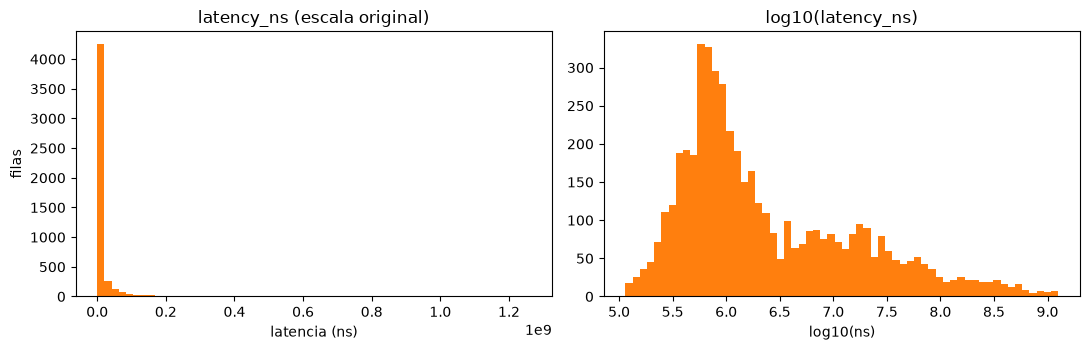

In [14]:
# Distribución de la variable objetivo (latencia_ns) en train
y = latencia_train["latency_ns"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=60, color="C1"); ax[0].set_title("latency_ns (escala original)")
ax[0].set_xlabel("latencia (ns)"); ax[0].set_ylabel("filas")
ax[1].hist(np.log10(y), bins=60, color="C1"); ax[1].set_title("log10(latency_ns)")
ax[1].set_xlabel("log10(ns)")
plt.tight_layout(); plt.show()

En las gráficas podemos observar la distribución de la variable objetivo (`latency_ns`) tanto en su escala original como después de aplicar la transformación logarítmica `log10`.

En la escala original, la distribución es muy asimétrica hacia la derecha, ya que la mayoría de las observaciones tienen valores bajos, mientras que existen algunos valores de latencia muy altos que alargan la distribución.

Al aplicar la transformación logarítmica, reducimos esta asimetría y visualizamos mejor la distribución de los datos. De esta forma, podemos observar con más claridad las diferencias entre las latencias y conocer mejor el comportamiento de la variable antes de utilizarla en el modelo.

In [15]:
# Cuánto varían las cinco ejecuciones de una misma configuración

# Se definen las columnas que representan la "configuración" (todas menos 'id' y 'latency_ns')
configuracion = [c for c in latencia_train.columns if c not in ['id', 'latency_ns']]

grupos_lat = latencia_train.groupby(configuracion)["latency_ns"]
ratio_max_min = grupos_lat.max() / grupos_lat.min()
std_log10 = grupos_lat.apply(lambda s: np.log10(s).std(ddof=1))

resumen_var = pd.DataFrame({
    "ratio_max_min": ratio_max_min,
    "std_log10_ns": std_log10,
})
print("Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):")
display(
    resumen_var.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T[[
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "90%",
        "max",
    ]]
)

# Ejemplo de una configuración y sus 5 latencias distintas
ejecuciones = grupos_lat.size()
ejemplo = ejecuciones[ejecuciones == 5].index[0]
ejemplo = (latencia_train[configuracion] == ejemplo).all(axis=1)
ejemplo = latencia_train[ejemplo][['block_size', 'n_jobs', 'iodepth', 'read_fraction', 'load_type', 'io_type', 'raid', 'n_disks', 'device_type', 'latency_ns']]
print("\nEjemplo de las 5 ejecuciones para una misma configuración:")
display(ejemplo)
latencias = ejemplo['latency_ns']

Resumen de variabilidad entre las 5 ejecuciones (1.000 configuraciones):


,count,mean,std,min,25%,50%,75%,90%,max
ratio_max_min,1000.0,1.287067,1.139653,1.000245,1.021795,1.068416,1.223296,1.572391,26.24800
std_log10_ns,1000.0,0.030703,0.053001,0.000044,0.003833,0.011891,0.035911,0.080515,0.62397



Ejemplo de las 5 ejecuciones para una misma configuración:


C:\Users\Usuario\AppData\Local\Temp\ipykernel_19932\175168891.py:32: Pandas4Warning: Operation with tuple is deprecated. In a future version these will be treated as scalar-like. To retain the old behavior, explicitly wrap in a Series instead.
  ejemplo = (latencia_train[configuracion] == ejemplo).all(axis=1)


,block_size,n_jobs,iodepth,read_fraction,load_type,io_type,raid,n_disks,device_type,latency_ns
408,4,2,11,23,random,read,4+1,24,nvme,121127.5
543,4,2,11,23,random,read,4+1,24,nvme,117519.0
3819,4,2,11,23,random,read,4+1,24,nvme,116699.0
4349,4,2,11,23,random,read,4+1,24,nvme,119568.5
4960,4,2,11,23,random,read,4+1,24,nvme,118525.0


La primera tabla muestra cuánto varía la latencia (`latency_ns`) entre las 5 repeticiones de cada una de las 1.000 configuraciones únicas. Para ello, se utilizan dos métricas:
* **`ratio_max_min`**: indica cuántas veces mayor es la latencia máxima respecto a la mínima de una misma configuración. Un valor cercano a 1 significa que las ejecuciones han tenido resultados muy similares, mientras que valores más altos indican una mayor diferencia entre ellas.
* **`std_log10_ns`**: mide la desviación típica de `log10(latency_ns)` dentro de cada configuración. Permite analizar la variabilidad teniendo en cuenta que las diferencias de latencia pueden ser multiplicativas y no siempre siguen una distribución simétrica.

### Resumen de variabilidad

En la mayoría de las configuraciones se observa una variabilidad bastante baja entre las cinco repeticiones. La mediana (`50%`) de `ratio_max_min` es 1.068, lo que significa que, en un caso típico, la ejecución más lenta tarda aproximadamente un 6,8 % más que la más rápida. Además, en el `75 %` de las configuraciones el ratio no supera 1.223. La mediana de `std_log10_ns` también es baja (0.0119), lo que confirma que, por lo general, las distintas ejecuciones ofrecen resultados bastante similares.

Sin embargo, hay algunas configuraciones que presentan diferencias mucho más importantes entre repeticiones. Esto se refleja en que la media de `ratio_max_min` (1.287) es superior a su mediana (1.068), lo que indica que existen algunos valores extremos que elevan el promedio. Aunque la mayoría de los casos son bastante estables, el percentil 90 alcanza 1.572 y el valor máximo llega a 26.248. Esto significa que, en alguna configuración concreta, la ejecución más lenta ha tardado más de 26 veces que la más rápida.

Estos resultados muestran que una misma configuración no siempre produce exactamente la misma latencia, ya que existen variaciones entre sus distintas ejecuciones, probablemente debido a la existencia de ruido.

### Ejemplo

La segunda tabla muestra un ejemplo concreto de la variabilidad de la latencia en las cinco ejecuciones de una configuración. En este caso, se puede ver que no varía demasiado.

**¿Qué hace difícil este problema?**

La predicción de la latencia es difícil debido a diferentes cosas:

- **Asimetría de su distribución:** La variable objetivo tiene un rango de valores muy amplio (desde aproximadamente $10^5$ hasta $10^9$ ns) y una distribución muy sesgada. Esto es importante porque el $MAE_{\log}$ calcula el error absoluto medio sobre el logaritmo decimal de la latencia:
   $$MAE_{\log} = \frac{1}{n} \sum_{i=1}^{n} \vert{}\log_{10} y_i - \log_{10} \hat{y}_i\vert{}$$
   A diferencia del $MAE$, que mide las diferencias absolutas en las unidades originales y hace que los errores en valores más altos tengan mayor peso, el $MAE_{\log}$ tiene en cuenta los errores relativos. De esta forma, evita que las latencias más elevadas condicionen tanto el resultado de la evaluación. Esto significa que un error multiplicativo del mismo tamaño (por ejemplo, desviarse por un factor de 1.26) recibe la misma penalización, independientemente de si se produce en latencias de microsegundos o de milisegundos.

- **La variabilidad entre ejecuciones de una misma configuración:** Como hemos visto en la tabla anterior, los resultados de las cinco repeticiones de una misma configuración varían un poco debido al ruido, lo que planteará la decisión de si entrenar el modelo con todas las filas o calcular un valor medio que represente cada configuración en el Ejercicio 3.

- **Que puedan existir relaciones no lineales e interacciones entre las características:** El rendimiento del almacenamiento depende de varios factores que se influyen entre sí, como el tamaño de bloque, la profundidad de cola, el número de hilos y el tipo de RAID. Por ello, es necesario utilizar modelos que puedan detectar cómo afectan sus distintas combinaciones al rendimiento.

- **Hay variables numéricas y categóricas:** Como el conjunto de datos combina ambos tipos de variables, es necesario realizar un preprocesamiento adecuado antes de entrenar el modelo. Para ello, se deberán transformar las variables categóricas mediante técnicas de codificación y escalar las numéricas para evitar que unas tengan más peso que otras. Esto es muy importante en KNN porque utiliza distancias para determinar qué configuraciones son más similares entre sí.

### 1(b) Protocolos de validación — ciberseguridad

In [16]:
# --- 1(b) Protocolos de validación en ciber ---------------------------------------
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import (StratifiedKFold, KFold, RepeatedStratifiedKFold,
                                     StratifiedShuffleSplit, cross_val_score)

# Datos: sin la columna id y con el objetivo aparte
X_ciber = ciber_train[X_CIBER]
y_ciber = ciber_train["attack_type"]

NOMINALES_CIBER = ["proto", "service", "conn_state"]
NUMERICAS_CIBER = [c for c in X_CIBER if c not in NOMINALES_CIBER]

# Modelo con el que se comparan los protocolos: KNN K=5, log1p + estandarizar.
# Todo el preprocesamiento va dentro del Pipeline: se ajusta solo con cada entrenamiento.
modelo_ciber_cv = Pipeline([
    ("pre", ColumnTransformer([
        ("nom", OneHotEncoder(handle_unknown="ignore"), NOMINALES_CIBER),
        ("num", Pipeline([("log", FunctionTransformer(np.log1p)),
                          ("esc", StandardScaler())]), NUMERICAS_CIBER),
    ])),
    ("knn", KNeighborsClassifier(n_neighbors=5)),
])

protocolos_ciber = {
    "Holdout 80/20 estrat.":   lambda s: StratifiedShuffleSplit(1, test_size=0.2, random_state=s),
    "5-fold sin estratificar": lambda s: KFold(5, shuffle=True, random_state=s),
    "5-fold estratificado":    lambda s: StratifiedKFold(5, shuffle=True, random_state=s),
    "10-fold estratificado":   lambda s: StratifiedKFold(10, shuffle=True, random_state=s),
    "5x3 estratificado":       lambda s: RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=s),
}

# Cada protocolo se repite con 8 semillas derivadas de SEMILLA: la dispersión entre
# semillas mide cuánto se puede fiar uno de la estimación.
N_SEMILLAS = 8
resultados = {}
for nombre, crear_cv in protocolos_ciber.items():
    medias = []
    for i in range(N_SEMILLAS):
        puntuaciones = cross_val_score(modelo_ciber_cv, X_ciber, y_ciber,
                                       cv=crear_cv(SEMILLA + i),
                                       scoring="f1_macro", n_jobs=-1)
        medias.append(puntuaciones.mean())
    resultados[nombre] = {"media": np.mean(medias),
                          "desv entre semillas": np.std(medias),
                          "rango": np.ptp(medias)}

tabla_protocolos_ciber = pd.DataFrame(resultados).T.round(4)
display(tabla_protocolos_ciber)

# Ejemplares de la clase rara en cada pliegue de validación (efecto de estratificar)
es_ransomware = (y_ciber == "ransomware").to_numpy()
for nombre, cv in [("5-fold sin estratificar", KFold(5, shuffle=True, random_state=SEMILLA)),
                   ("5-fold estratificado", StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
                   ("10-fold estratificado", StratifiedKFold(10, shuffle=True, random_state=SEMILLA))]:
    print(f"{nombre:25s} ransomware por pliegue:",
          [int(es_ransomware[val].sum()) for _, val in cv.split(X_ciber, y_ciber)])

,media,desv entre semillas,rango
Holdout 80/20 estrat.,0.9162,0.0095,0.0250
5-fold sin estratificar,0.9188,0.0024,0.0081
5-fold estratificado,0.9188,0.0028,0.0087
10-fold estratificado,0.9210,0.0015,0.0051
5x3 estratificado,0.9193,0.0014,0.0042


5-fold sin estratificar   ransomware por pliegue: [8, 7, 18, 7, 10]
5-fold estratificado      ransomware por pliegue: [10, 10, 10, 10, 10]
10-fold estratificado     ransomware por pliegue: [5, 5, 5, 5, 5, 5, 5, 5, 5, 5]


### 1(b) Protocolos de latencia_train

## Ejercicio 2. Modelos de referencia: ZeroR y OneR

*(TODO)*

## Ejercicio 3. KNN de scikit-learn

*(TODO)*

## Ejercicio 4. Vuestro KNN clasificador y la competición de ciberseguridad

*(TODO)*

## Ejercicio 5. Vuestro KNN regresor y la competición de latencia

*(TODO)*

## Envío final

**Esta debe ser la última celda del cuaderno.** Entrena vuestros dos modelos finales, que llevan
dentro vuestro KNN propio, con **todo** el conjunto de entrenamiento y escribe los dos ficheros.
Si en latencia entrenáis con un resumen de las cinco ejecuciones de cada configuración, calculadlo
aquí, en `X_final_latencia` e `y_final_latencia`. Lo que subáis a Kaggle como envío final tiene que
ser exactamente lo que escribe esta celda: el profesor volverá a ejecutar el cuaderno y lo
comprobará. No cambiéis los nombres de los modelos ni de los ficheros.

In [17]:
# --- ENVÍO FINAL: esta celda es la ÚLTIMA del cuaderno ---------------------------
modelo_final_ciber = None   # TODO: vuestro Pipeline con vuestro KNN clasificador
modelo_final_latencia = None   # TODO: vuestro Pipeline con vuestro KNN regresor

# Datos de entrenamiento de los modelos finales: todo el entrenamiento.
X_final_ciber, y_final_ciber = ciber_train[X_CIBER], ciber_train["attack_type"]
X_final_latencia, y_final_latencia = latencia_train[X_LATENCIA], latencia_train["latency_ns"]

modelo_final_ciber.fit(X_final_ciber, y_final_ciber)
modelo_final_latencia.fit(X_final_latencia, y_final_latencia)

envio_ciber = pd.DataFrame({"id": ciber_test["id"],
                            "attack_type": modelo_final_ciber.predict(ciber_test[X_CIBER])})
envio_latencia = pd.DataFrame({"id": latencia_test["id"],
                               "latency_ns": modelo_final_latencia.predict(latencia_test[X_LATENCIA])})
assert (envio_latencia["latency_ns"] > 0).all(), "la latencia predicha tiene que ser positiva"
envio_ciber.to_csv("envio_ciber.csv", index=False)
envio_latencia.to_csv("envio_latencia.csv", index=False)
print("envio_ciber.csv   ", envio_ciber.shape)
print("envio_latencia.csv", envio_latencia.shape)

AttributeError: 'NoneType' object has no attribute 'fit'